# SOTA Transfer Learning & Fine-Tuning

Two lightweight, mobile/edge-friendly ImageNet-pretrained backbones, adapted to the 9 RealWaste classes:

- **SOTA 1: MobileNetV2** — depthwise-separable convs + inverted residuals, designed specifically for mobile inference.
- **SOTA 2: SqueezeNet1_1** — "fire modules" (squeeze + expand 1x1/3x3 convs) built to match AlexNet-level accuracy with far fewer parameters.

Both are trained on the exact same 70/15/15 split as Model A / Model B, in two stages:

1. **Transfer learning** (20 epochs, Adam `lr=0.001`, the optimizer justified in the optimizer tuning notebook): the ImageNet backbone is **frozen** and only the new 9-class head is trained. A randomly initialised head would push large, noisy gradients into the backbone, so it is trained on its own first.
2. **Fine-tuning** (10 epochs, Adam `lr=0.0001`): the last backbone blocks are **unfrozen** (`FINE_TUNE_BLOCKS` in `sota_models.py`: the last two inverted-residual blocks + final 1x1 conv of MobileNetV2, the last two Fire modules of SqueezeNet) and trained together with the head. The 10x lower learning rate lets the highest-level, most ImageNet-specific features adapt to waste images without wiping out what they learned. The early blocks (generic edge/texture detectors, which transfer well) stay frozen, which also keeps the trainable parameter count reasonable for a 3.3k-image training set.

In [1]:
import matplotlib.pyplot as plt
import torch

from data_loader import CLASS_NAMES, get_dataloaders, set_seed
from sota_models import MobileNetV2Classifier, SqueezeNetClassifier, unfreeze_last_blocks
from train_utils import count_params, evaluate_classification, model_size_kb, train_model

EPOCHS = 20             # stage 1: head only, backbone frozen
FINE_TUNE_EPOCHS = 10   # stage 2: last backbone blocks unfrozen
FINE_TUNE_LR = 1e-4
train_loader, val_loader, test_loader = get_dataloaders(batch_size=32)

In [2]:
set_seed()
sota_models = {
    "SOTA 1 (MobileNetV2)": MobileNetV2Classifier(),
    "SOTA 2 (SqueezeNet)": SqueezeNetClassifier(),
}

for name, model in sota_models.items():
    total = sum(p.numel() for p in model.parameters())
    trainable = count_params(model)
    print(f"{name}: {total:,} total params, {trainable:,} trainable (head only, base frozen)")

SOTA 1 (MobileNetV2): 2,235,401 total params, 11,529 trainable (head only, base frozen)
SOTA 2 (SqueezeNet): 727,113 total params, 4,617 trainable (head only, base frozen)


## Stage 1: transfer learning (backbone frozen, head only)

In [3]:
histories = {}
stage1_metrics = {}
for name, model in sota_models.items():
    print(f"\n=== {name} ===")
    trainable_params = filter(lambda p: p.requires_grad, model.parameters())
    optimizer = torch.optim.Adam(trainable_params, lr=0.001)
    history, avg_epoch_time = train_model(model, train_loader, val_loader, optimizer, epochs=EPOCHS)
    histories[name] = {"history": history, "avg_epoch_time": avg_epoch_time}
    stage1_metrics[name] = evaluate_classification(model, test_loader)


=== SOTA 1 (MobileNetV2) ===


epoch 1/20  train_loss 1.6343 train_acc 0.439  val_loss 1.3543 val_acc 0.563


epoch 2/20  train_loss 1.2471 train_acc 0.589  val_loss 1.2846 val_acc 0.558


epoch 3/20  train_loss 1.1018 train_acc 0.635  val_loss 1.1881 val_acc 0.614


epoch 4/20  train_loss 1.0299 train_acc 0.664  val_loss 1.1791 val_acc 0.596


...

epoch 16/20  train_loss 0.9918 train_acc 0.680  val_loss 1.0420 val_acc 0.659


epoch 17/20  train_loss 0.9572 train_acc 0.690  val_loss 1.0801 val_acc 0.650


epoch 18/20  train_loss 0.9289 train_acc 0.695  val_loss 1.0192 val_acc 0.663


epoch 19/20  train_loss 0.9642 train_acc 0.686  val_loss 1.0303 val_acc 0.657


epoch 20/20  train_loss 0.9276 train_acc 0.692  val_loss 1.0428 val_acc 0.656


## Stage 2: fine-tuning (last backbone blocks unfrozen)

Continues from the stage-1 weights. Only the parameters that are now trainable are handed to the new optimizer.

In [4]:
for name, model in sota_models.items():
    head_only = count_params(model)
    unfreeze_last_blocks(model)
    histories[name]["head_params"] = head_only
    print(f"\n=== {name}: {head_only:,} -> {count_params(model):,} trainable params ===")
    trainable_params = filter(lambda p: p.requires_grad, model.parameters())
    optimizer = torch.optim.Adam(trainable_params, lr=FINE_TUNE_LR)
    history, avg_epoch_time = train_model(model, train_loader, val_loader, optimizer, epochs=FINE_TUNE_EPOCHS)
    for key in history:
        histories[name]["history"][key] += history[key]
    histories[name]["fine_tune_epoch_time"] = avg_epoch_time


=== SOTA 1 (MobileNetV2): 11,529 -> 1,217,609 trainable params ===


epoch 1/10  train_loss 0.6992 train_acc 0.757  val_loss 1.0980 val_acc 0.652


epoch 2/10  train_loss 0.6074 train_acc 0.794  val_loss 1.0830 val_acc 0.664


epoch 3/10  train_loss 0.5173 train_acc 0.822  val_loss 1.0228 val_acc 0.663


epoch 4/10  train_loss 0.4576 train_acc 0.848  val_loss 0.9925 val_acc 0.691


...

epoch 6/10  train_loss 0.6080 train_acc 0.795  val_loss 0.9015 val_acc 0.702


epoch 7/10  train_loss 0.5438 train_acc 0.818  val_loss 0.8768 val_acc 0.690


epoch 8/10  train_loss 0.5185 train_acc 0.827  val_loss 0.8800 val_acc 0.721


epoch 9/10  train_loss 0.4957 train_acc 0.833  val_loss 0.8744 val_acc 0.729


epoch 10/10  train_loss 0.4505 train_acc 0.848  val_loss 0.9231 val_acc 0.722


## Training / validation curves (both stages)

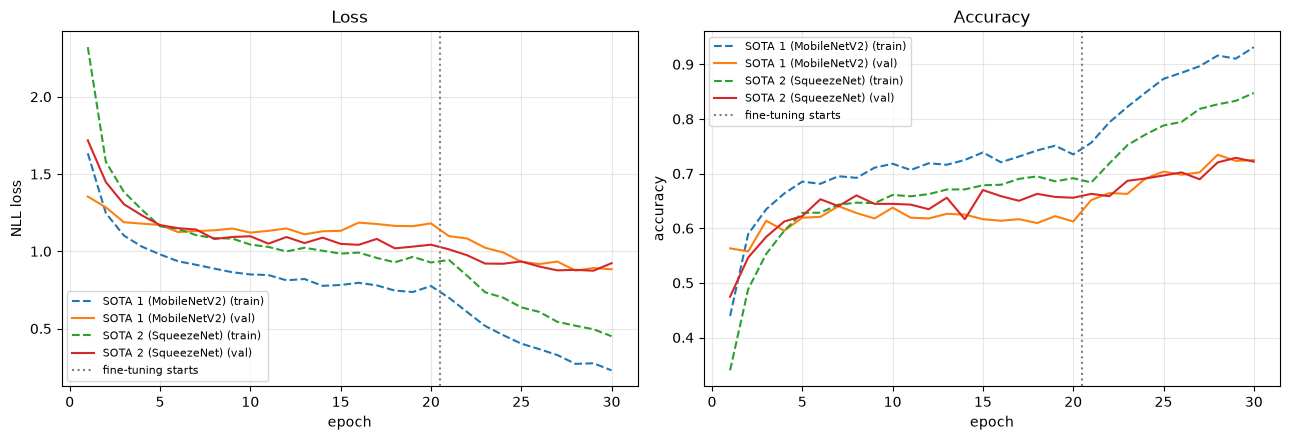

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
epochs_range = range(1, EPOCHS + FINE_TUNE_EPOCHS + 1)

for name, result in histories.items():
    h = result["history"]
    axes[0].plot(epochs_range, h["train_loss"], linestyle="--", label=f"{name} (train)")
    axes[0].plot(epochs_range, h["val_loss"], linestyle="-", label=f"{name} (val)")
    axes[1].plot(epochs_range, h["train_acc"], linestyle="--", label=f"{name} (train)")
    axes[1].plot(epochs_range, h["val_acc"], linestyle="-", label=f"{name} (val)")

axes[0].set_title("Loss"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("NLL loss")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy")
for ax in axes:
    ax.axvline(EPOCHS + 0.5, color="gray", linestyle=":", label="fine-tuning starts")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Test-set evaluation

SOTA 1 (MobileNetV2): test_acc=0.718 (stage 1 only: 0.633) precision=0.720 recall=0.718
    2,235,401 total params, 11,529 trained in stage 1, 1,217,609 in stage 2, size=8.76 MB, 7.45 s/epoch (stage 1), 9.58 s/epoch (stage 2)
                     precision    recall  f1-score   support

          Cardboard      0.731     0.710     0.721        69
      Food Organics      0.904     0.770     0.832        61
              Glass      0.708     0.730     0.719        63
              Metal      0.648     0.773     0.705       119
Miscellaneous Trash      0.582     0.520     0.549        75
              Paper      0.761     0.720     0.740        75
            Plastic      0.730     0.667     0.697       138
      Textile Trash      0.682     0.638     0.659        47
         Vegetation      0.797     0.955     0.869        66

           accuracy                          0.718       713
          macro avg      0.727     0.720     0.721       713
       weighted avg      0.720     0.718

SOTA 2 (SqueezeNet): test_acc=0.732 (stage 1 only: 0.679) precision=0.741 recall=0.732
    727,113 total params, 4,617 trained in stage 1, 390,793 in stage 2, size=2.79 MB, 4.10 s/epoch (stage 1), 4.28 s/epoch (stage 2)
                     precision    recall  f1-score   support

          Cardboard      0.879     0.739     0.803        69
      Food Organics      0.789     0.738     0.763        61
              Glass      0.854     0.651     0.739        63
              Metal      0.703     0.756     0.729       119
Miscellaneous Trash      0.627     0.560     0.592        75
              Paper      0.718     0.747     0.732        75
            Plastic      0.641     0.790     0.708       138
      Textile Trash      0.738     0.660     0.697        47
         Vegetation      0.877     0.864     0.870        66

           accuracy                          0.732       713
          macro avg      0.759     0.723     0.737       713
       weighted avg      0.741     0.732     0

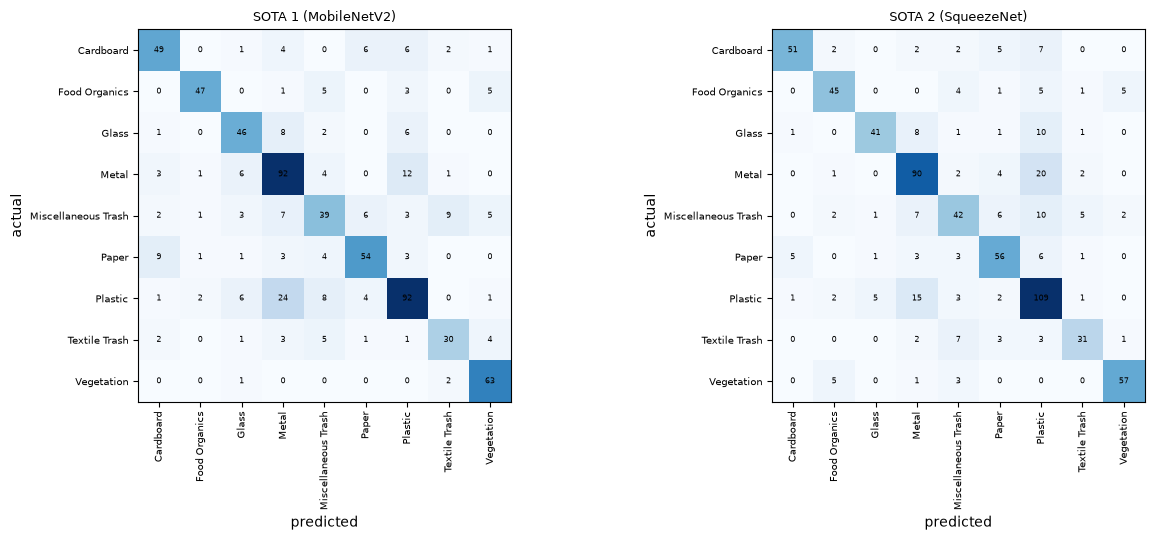

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

sota_results = {}
for ax, (name, model) in zip(axes, sota_models.items()):
    metrics = evaluate_classification(model, test_loader, class_names=CLASS_NAMES)
    metrics["total_params"] = sum(p.numel() for p in model.parameters())
    metrics["trainable_params"] = count_params(model)
    metrics["size_kb"] = model_size_kb(model)
    metrics["avg_epoch_time"] = histories[name]["avg_epoch_time"]
    metrics["fine_tune_epoch_time"] = histories[name]["fine_tune_epoch_time"]
    sota_results[name] = metrics

    print(f"{name}: test_acc={metrics['accuracy']:.3f} (stage 1 only: {stage1_metrics[name]['accuracy']:.3f}) "
          f"precision={metrics['precision']:.3f} recall={metrics['recall']:.3f}")
    print(f"    {metrics['total_params']:,} total params, {histories[name]['head_params']:,} trained in stage 1, "
          f"{metrics['trainable_params']:,} in stage 2, size={metrics['size_kb'] / 1024:.2f} MB, "
          f"{metrics['avg_epoch_time']:.2f} s/epoch (stage 1), {metrics['fine_tune_epoch_time']:.2f} s/epoch (stage 2)")
    print(metrics["report"])

    im = ax.imshow(metrics["confusion_matrix"], cmap="Blues")
    ax.set_xticks(range(9)); ax.set_xticklabels(CLASS_NAMES, rotation=90, fontsize=7)
    ax.set_yticks(range(9)); ax.set_yticklabels(CLASS_NAMES, fontsize=7)
    ax.set_xlabel("predicted"); ax.set_ylabel("actual")
    ax.set_title(name, fontsize=9)
    for i in range(9):
        for j in range(9):
            ax.text(j, i, metrics["confusion_matrix"][i, j], ha="center", va="center", fontsize=6)

plt.tight_layout()
plt.show()

## Discussion

**Effect of fine-tuning.** Training only the new head (stage 1) plateaus early: from about epoch 6 the validation accuracy stops improving (around 62% for MobileNetV2, 65% for SqueezeNet), because a frozen ImageNet feature extractor can only be re-weighted, not adapted. Unfreezing the last backbone blocks (stage 2, at a 10x lower learning rate) immediately pushes the validation loss down again and lifts test accuracy for both models:

| Model | Test acc, stage 1 (frozen backbone) | Test acc, stage 2 (fine-tuned) | Trainable params in stage 2 | Size on disk |
|---|---|---|---|---|
| MobileNetV2 | 63.3% | **71.8%** (+8.5 pts) | 1,217,609 of 2,235,401 | 8.76 MB |
| SqueezeNet1_1 | 67.9% | **73.2%** (+5.3 pts) | 390,793 of 727,113 | 2.79 MB |

MobileNetV2 gains the most. With a frozen backbone it was the weaker of the two, which fits the resolution mismatch below: its last blocks see only a 2x2 feature map at 64x64 input, and fine-tuning lets exactly those blocks adapt.

**What fine-tuning costs.** It starts to overfit: during stage 2 the training accuracy climbs to 93% (MobileNetV2) and 85% (SqueezeNet) while validation accuracy levels off around 72-73%, which is expected with over a million trainable parameters and 3.3k training images. Ten epochs at `lr=1e-4` is a reasonable stopping point; training longer would need data augmentation or early stopping. Each training epoch is also slower (MobileNetV2 7.45 -> 9.58 s, SqueezeNet 4.10 -> 4.28 s on this CPU) because the backward pass now runs through the unfrozen blocks. Inference cost and model size do not change: fine-tuning changes weight values, not the architecture.

**Per-class behaviour.** Both models are best on Vegetation (F1 0.87) and worst on Miscellaneous Trash (F1 0.55 / 0.59, recall 0.52 / 0.56), a catch-all class with no consistent appearance.

**Input resolution.** Both backbones were pretrained on ImageNet at 224x224; feeding them the same 64x64 input used everywhere else in this assignment (for a fair, apples-to-apples comparison against Model A/B) discards most of the spatial detail their convolutional stages were designed to exploit, so their accuracy here understates what they'd reach at their native resolution. The comparison against Model B on accuracy, memory and compute is in `main_report.ipynb`.